In [1]:
%pip install -U "qiskit[visualization]" qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


In [3]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.visualization import plot_histogram
from IPython.display import display
from getpass import getpass
import pandas as pd

SHOTS = 100

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum instance CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Connected to IBM Quantum successfully.")
print("Active instance:", service.active_instance())

Enter your IBM Quantum API key:  ········
Enter your IBM Quantum instance CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/4db3032ff9574ab8b189d65aca927eb7:afda762a-3892-48ce-beff-b56cb09b4f57::


qiskit_runtime_service._discover_account:WARNING:2026-10-10 15:37:54,277: Loading account with the given token. A saved account will not be used.


Connected to IBM Quantum successfully.
Active instance: crn:v1:bluemix:public:quantum-computing:us-east:a/4db3032ff9574ab8b189d65aca927eb7:afda762a-3892-48ce-beff-b56cb09b4f57::


In [5]:
backend = service.least_busy(
    min_num_qubits=1,
    operational=True,
    simulator=False
)

print("Selected quantum computer:", backend.name)
print("Backend status:", backend.status().status_msg)

Selected quantum computer: ibm_fez
Backend status: active


## Predictions Before Execution

**Circuit A**  
One X gate changes the initial state |0⟩ to |1⟩.  
Ideal prediction: 100 counts of 1.

**Circuit B**  
Two X gates return the qubit to |0⟩.  
Ideal prediction: 100 counts of 0.

**Circuit C**  
One H gate creates an equal superposition of |0⟩ and |1⟩.  
Ideal prediction: approximately 50 counts of each outcome.

Real quantum hardware may produce slightly different results due to noise.

## Predictions Before Execution

**Circuit A**  
One X gate changes the initial state |0⟩ to |1⟩.  
Ideal prediction: 100 counts of 1.

**Circuit B**  

Two X gates return the qubit to |0⟩.  
Ideal prediction: 100 counts of 0.

**Circuit C**  
One H gate creates an equal superposition of |0⟩ and |1⟩.  
Ideal prediction: approximately 50 counts of each outcome.

Real quantum hardware may produce slightly different results due to noise.

Circuit A


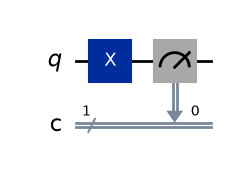

Circuit B


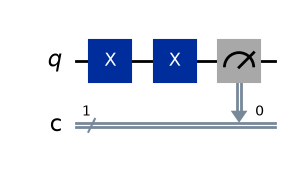

Circuit C


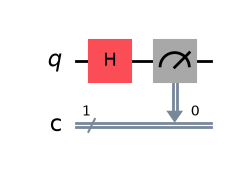

In [6]:
# Circuit A: One X gate
circuit_a = QuantumCircuit(1, 1)
circuit_a.x(0)
circuit_a.measure(0, 0)

# Circuit B: Two X gates
circuit_b = QuantumCircuit(1, 1)
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

# Circuit C: One H gate
circuit_c = QuantumCircuit(1, 1)
circuit_c.h(0)
circuit_c.measure(0, 0)

circuits = [circuit_a, circuit_b, circuit_c]

for name, circuit in zip(["A", "B", "C"], circuits):
    print(f"Circuit {name}")
    display(circuit.draw("mpl"))

In [7]:
pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

compiled_circuits = pass_manager.run(circuits)

print("All three circuits compiled successfully.")


All three circuits compiled successfully.


In [8]:
sampler = SamplerV2(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=SHOTS
)

print("Job submitted successfully.")
print("Job ID:", job.job_id())
print("Waiting for results...")

result = job.result()

print("Execution completed.")


C:\Users\SUSEELA\AppData\Local\Temp\ipykernel_11760\1845012513.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job submitted successfully.
Job ID: db5riro4qg6s73c3t2rg
Waiting for results...
Execution completed.


In [9]:
sampler = SamplerV2(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=SHOTS
)

print("Job submitted successfully.")
print("Job ID:", job.job_id())
print("Waiting for results...")

result = job.result()

print("Execution completed.")

C:\Users\SUSEELA\AppData\Local\Temp\ipykernel_11760\3537113364.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job submitted successfully.
Job ID: db5rj5cvf2bc73d0arug
Waiting for results...
Execution completed.


In [12]:
# Extract measurement counts

print("Available result fields:", result[0].data.keys())

counts_a = result[0].data.c.get_counts()
counts_b = result[1].data.c.get_counts()
counts_c = result[2].data.c.get_counts()

print("Circuit A:", counts_a)
print("Circuit B:", counts_b)

print("Circuit C:", counts_c)
print(result[0].data.keys())


Available result fields: dict_keys(['c'])
Circuit A: {'1': 96, '0': 4}
Circuit B: {'0': 98, '1': 2}
Circuit C: {'1': 49, '0': 51}
dict_keys(['c'])


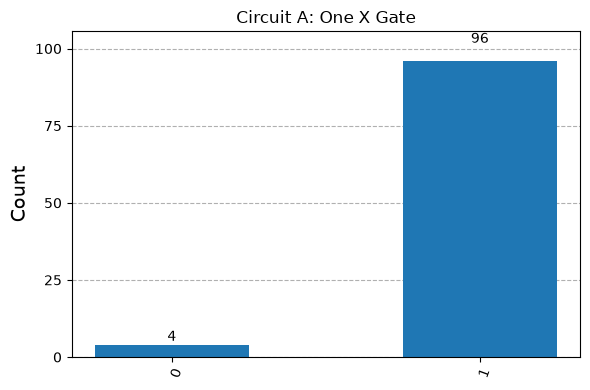

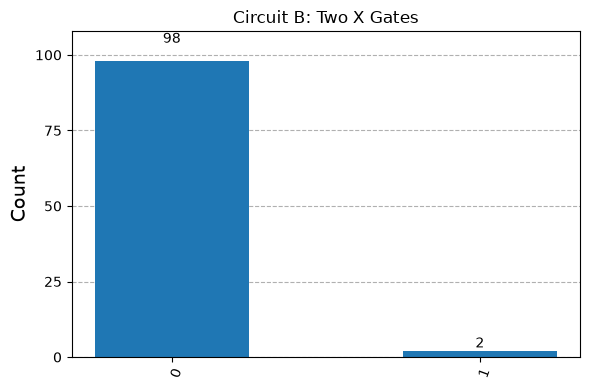

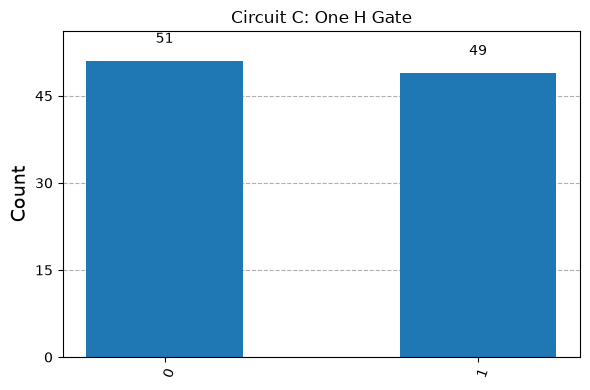

In [13]:
display(plot_histogram(
    counts_a,
    title="Circuit A: One X Gate",
    figsize=(6, 4)
))

display(plot_histogram(
    counts_b,
    title="Circuit B: Two X Gates",
    figsize=(6, 4)
))

display(plot_histogram(
    counts_c,
    title="Circuit C: One H Gate",
    figsize=(6, 4)
))

In [15]:
comparison = pd.DataFrame([
    {
        "Circuit": "A",
        "Gates": "X",
        "Ideal Prediction": "100 outcomes of 1",
        "Actual Counts": str(counts_a),
        "Total Shots": sum(counts_a.values())
    },
    {
        "Circuit": "B",
        "Gates": "X, X",
        "Ideal Prediction": "100 outcomes of 0",
        "Actual Counts": str(counts_b),
        "Total Shots": sum(counts_b.values())
    },
    {
        "Circuit": "C",
        "Gates": "H",
        "Ideal Prediction": "Approximately 50 each",
        "Actual Counts": str(counts_c),
        "Total Shots": sum(counts_c.values())
    }
])

display(comparison)

,Circuit,Gates,Ideal Prediction,Actual Counts,Total Shots
0,A,X,100 outcomes of 1,"{'1': 96, '0': 4}",100
1,B,"X, X",100 outcomes of 0,"{'0': 98, '1': 2}",100
2,C,H,Approximately 50 each,"{'1': 49, '0': 51}",100


## Conclusion

The three quantum circuits were executed on IBM Quantum hardware
using 100 shots per circuit.

Circuit A was expected to produce the outcome 1 after one X gate.
Circuit B was expected to produce the outcome 0 after two X gates.
Circuit C was expected to produce both outcomes with approximately
equal probabilities after one H gate.

The measured results were compared with the ideal predictions.
Any differences may be caused by quantum hardware noise and gate
or measurement errors.

The experiment demonstrates how quantum gates affect measurement
outcomes.